# AI-Based Student Performance Risk Predictor — ANN Training Notebook

## 1. Project objective

Build and evaluate a **feed-forward Artificial Neural Network (ANN)** in Keras/TensorFlow that predicts a student's
**performance category (Low / Medium / High)** from academic and behavioural features, and compare it with a
traditional machine-learning **baseline (Logistic Regression)**.

This notebook is the *training* side of the project. It:

1. inspects and explores the supplied dataset (`data/student_data.csv`),
2. prepares the data without leaking test information,
3. trains the baseline and the ANN,
4. evaluates both on the **same untouched test set**,
5. saves the model, scaler, class mapping, metrics and report that `app.py` (Streamlit) and `api.py` (FastAPI) load later.

> **Important:** every number and chart below is produced by running the code. Nothing is typed in by hand.
> Predictions are statistical estimates for learning purposes, not guarantees about any real student.

**How to run:** from the project root, `jupyter nbconvert --to notebook --execute --inplace notebooks/ann_training.ipynb`
(or open it in Jupyter and choose *Run All*).

In [1]:
import os, sys, json, platform, subprocess, warnings
from pathlib import Path
from datetime import datetime, timezone

os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"          # hide verbose TensorFlow logs
os.environ["TF_DETERMINISTIC_OPS"] = "1"          # more reproducible results

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import sklearn
import tensorflow as tf
from tensorflow import keras

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             confusion_matrix, classification_report)

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook")

SEED = 42
keras.utils.set_random_seed(SEED)                  # seeds Python, NumPy and TensorFlow together
tf.config.experimental.enable_op_determinism()

# Work out the project root whether the notebook is run from the root or from notebooks/
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_PATH = PROJECT_ROOT / "data" / "student_data.csv"
MODEL_DIR = PROJECT_ROOT / "models"
REPORT_DIR = PROJECT_ROOT / "reports"
MODEL_DIR.mkdir(exist_ok=True); REPORT_DIR.mkdir(exist_ok=True)
sys.path.insert(0, str(PROJECT_ROOT))

ENV = {
    "python": platform.python_version(), "tensorflow": tf.__version__, "keras": keras.__version__,
    "scikit-learn": sklearn.__version__, "numpy": np.__version__, "pandas": pd.__version__,
    "joblib": joblib.__version__,
}
print("Project root:", PROJECT_ROOT)
print("Environment :", ENV)

I0000 00:00:1792258390.906823    4433 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792258390.907540    4433 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


I0000 00:00:1792258392.357862    4433 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792258392.358242    4433 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


Project root: /home/claude/student-performance-ann
Environment : {'python': '3.12.3', 'tensorflow': '2.21.0', 'keras': '3.15.1', 'scikit-learn': '1.8.0', 'numpy': '2.4.4', 'pandas': '3.0.2', 'joblib': '1.5.3'}


## 2. Dataset loading

We load the CSV that was supplied with the assignment. We do **not** replace or modify it.

In [2]:
df = pd.read_csv(DATA_PATH)
df.head()

,student_id,age,attendance_pct,study_hours_per_week,previous_score,assignment_completion_pct,internal_assessment_score,participation_score,sleep_hours_per_day,extracurricular_hours_per_week,failed_subjects,performance_category
0,STU21500,24,73.8,7.9,58.3,100.0,55.6,4.7,4.9,5.0,0,Low
1,STU16476,19,58.1,3.9,61.5,100.0,55.5,8.8,5.3,0.0,1,Low
2,STU23168,18,77.5,24.5,86.2,66.9,69.3,8.3,6.6,7.1,0,High
3,STU10863,17,76.1,17.1,78.8,75.7,62.5,8.4,8.0,7.0,1,High
4,STU15971,22,86.3,4.6,76.2,79.6,72.6,5.5,6.4,2.0,0,Low


## 3. Dataset inspection

Before modelling we check the shape, column names, data types, missing values, duplicates, whether
`student_id` is unique, the class balance and the numeric ranges.

In [3]:
print("Shape (rows, columns):", df.shape)
print("\nColumn names:", list(df.columns))
print("\nData types:\n", df.dtypes.to_string())
print("\nMissing values per column:\n", df.isna().sum().to_string())
print("\nFully duplicated rows              :", df.duplicated().sum())
print("Duplicated rows ignoring student_id:", df.drop(columns="student_id").duplicated().sum())
print("Unique student_id values           :", df["student_id"].nunique(), "of", len(df))
print("\nTarget class distribution:")
print(pd.concat([df["performance_category"].value_counts().rename("count"),
                 (df["performance_category"].value_counts(normalize=True) * 100).round(2).rename("percent")], axis=1))

Shape (rows, columns): (15000, 12)

Column names: ['student_id', 'age', 'attendance_pct', 'study_hours_per_week', 'previous_score', 'assignment_completion_pct', 'internal_assessment_score', 'participation_score', 'sleep_hours_per_day', 'extracurricular_hours_per_week', 'failed_subjects', 'performance_category']

Data types:
 student_id                            str
age                                 int64
attendance_pct                    float64
study_hours_per_week              float64
previous_score                    float64
assignment_completion_pct         float64
internal_assessment_score         float64
participation_score               float64
sleep_hours_per_day               float64
extracurricular_hours_per_week    float64
failed_subjects                     int64
performance_category                  str

Missing values per column:
 student_id                        0
age                               0
attendance_pct                    0
study_hours_per_week            

In [4]:
print("Descriptive statistics of the numeric columns:")
display(df.describe().T.round(2))

ranges = df.drop(columns=["student_id", "performance_category"]).agg(["min", "max"]).T
ranges["n_unique"] = df[ranges.index].nunique()
print("Numeric feature ranges (these also tell us which input limits make sense):")
display(ranges)

Descriptive statistics of the numeric columns:


,count,mean,std,min,25%,50%,75%,max
age,15000.0,20.47,2.28,17.0,18.0,20.0,22.0,24.0
attendance_pct,15000.0,77.94,11.67,45.0,70.0,77.9,86.1,100.0
study_hours_per_week,15000.0,15.17,6.84,2.0,10.3,15.1,19.8,40.0
previous_score,15000.0,66.65,14.74,25.0,56.8,66.6,76.6,100.0
assignment_completion_pct,15000.0,75.35,15.89,20.0,64.4,75.9,87.5,100.0
internal_assessment_score,15000.0,64.83,15.85,20.0,54.1,64.7,75.8,100.0
participation_score,15000.0,6.15,1.95,1.0,4.8,6.2,7.5,10.0
sleep_hours_per_day,15000.0,6.79,1.10,4.0,6.1,6.8,7.5,10.0
extracurricular_hours_per_week,15000.0,5.12,3.29,0.0,2.6,5.0,7.4,18.0
failed_subjects,15000.0,0.80,0.90,0.0,0.0,1.0,1.0,5.0


Numeric feature ranges (these also tell us which input limits make sense):


,min,max,n_unique
age,17.0,24.0,8
attendance_pct,45.0,100.0,545
study_hours_per_week,2.0,40.0,353
previous_score,25.0,100.0,740
assignment_completion_pct,20.0,100.0,721
internal_assessment_score,20.0,100.0,780
participation_score,1.0,10.0,91
sleep_hours_per_day,4.0,10.0,61
extracurricular_hours_per_week,0.0,18.0,169
failed_subjects,0.0,5.0,6


## 4. Data cleaning

What we check and why:

* **Missing values** – a neural network cannot take `NaN`. If any existed we would have to impute them (using
  statistics from the *training* rows only). The check below fails loudly if that situation ever occurs.
* **Duplicates** – duplicated students could land in both train and test sets and inflate the test score.
* **Impossible values** – e.g. a percentage above 100.
* **Identifier** – `student_id` only labels a row. It carries no academic meaning, so it will **not** be a feature.

We do **not** alter any feature value.

In [5]:
PERCENT_COLS = ["attendance_pct", "assignment_completion_pct"]
SCORE_COLS = ["previous_score", "internal_assessment_score"]

assert df.isna().sum().sum() == 0, "Missing values found - add training-set imputation before continuing"
assert df.duplicated().sum() == 0, "Duplicate rows found - drop them before splitting"
assert df["student_id"].is_unique, "student_id is not unique"
assert df[PERCENT_COLS + SCORE_COLS].min().min() >= 0 and df[PERCENT_COLS + SCORE_COLS].max().max() <= 100
assert df["participation_score"].between(0, 10).all()
assert df["sleep_hours_per_day"].between(0, 24).all()
assert (df["failed_subjects"] >= 0).all()
assert df["student_id"].str.match(r"^STU\d+$").all()

print("All checks passed: no missing values, no duplicates, unique ids, all values in valid ranges.")
print("Rows kept:", len(df), "(nothing removed or changed)")

All checks passed: no missing values, no duplicates, unique ids, all values in valid ranges.
Rows kept: 15000 (nothing removed or changed)


## 5. Exploratory Data Analysis (EDA)

These charts are descriptive. We use them to understand the data, not to pick or discard rows.

### 5.1 Class distribution
We need to know whether the three classes are balanced, because with imbalanced classes plain accuracy can be misleading.

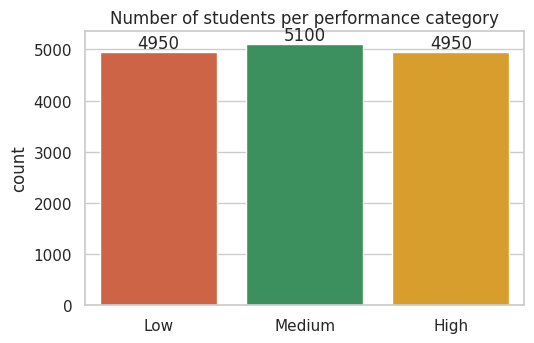

In [6]:
CLASS_ORDER = ["Low", "Medium", "High"]
fig, ax = plt.subplots(figsize=(5.5, 3.6))
sns.countplot(data=df, x="performance_category", order=CLASS_ORDER, palette=["#e4572e", "#f3a712", "#2e9e5b"], hue="performance_category", legend=False, ax=ax)
for c in ax.containers:
    ax.bar_label(c)
ax.set_title("Number of students per performance category"); ax.set_xlabel("")
plt.tight_layout(); plt.show()

### 5.2 Feature distributions
Histograms show the shape and scale of every input. The features live on very different scales
(e.g. `failed_subjects` is 0–5 while `previous_score` is 25–100), which matters for the ANN (see section 8).

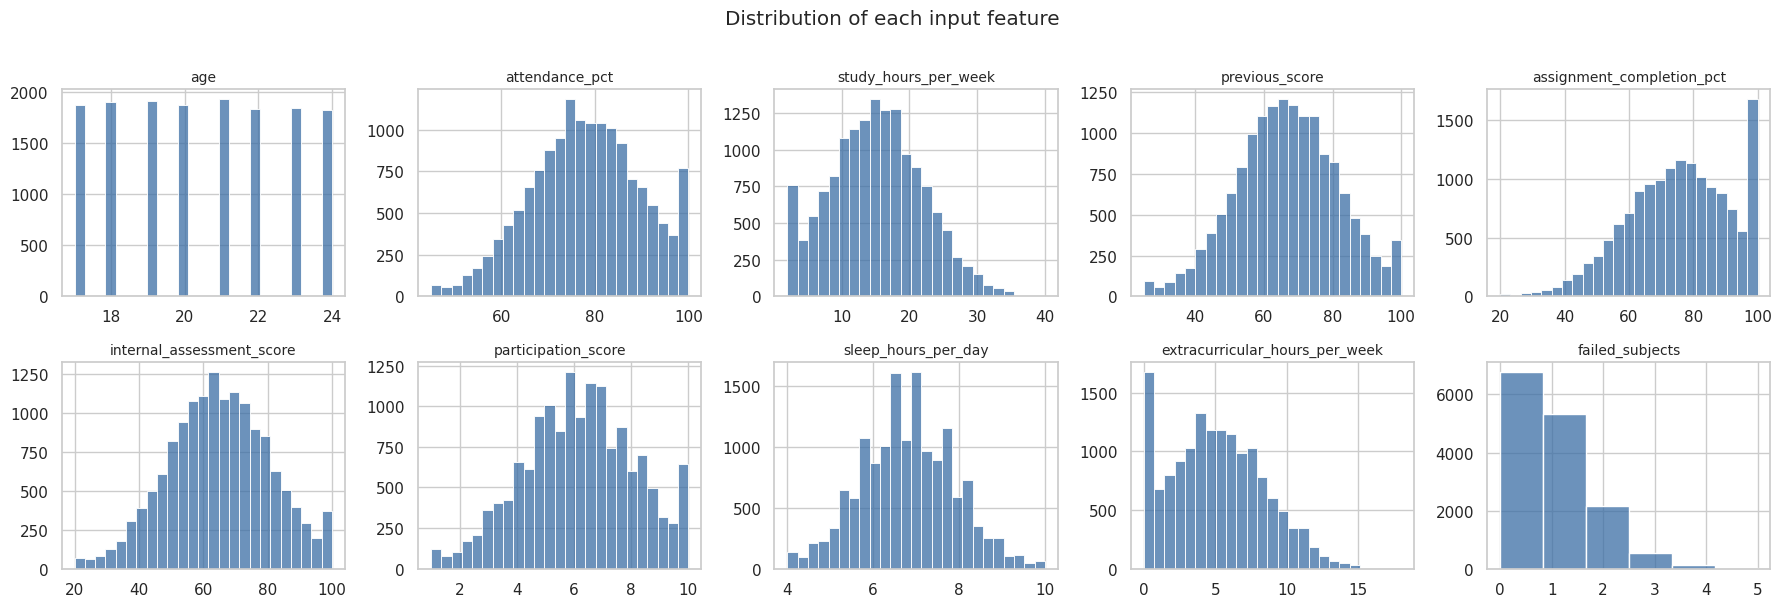

In [7]:
FEATURES = ["age", "attendance_pct", "study_hours_per_week", "previous_score", "assignment_completion_pct",
            "internal_assessment_score", "participation_score", "sleep_hours_per_day",
            "extracurricular_hours_per_week", "failed_subjects"]
fig, axes = plt.subplots(2, 5, figsize=(18, 6))
for ax, col in zip(axes.ravel(), FEATURES):
    sns.histplot(df[col], bins=25 if col != "failed_subjects" else 6, ax=ax, color="#3b6ea5")
    ax.set_title(col, fontsize=10); ax.set_xlabel(""); ax.set_ylabel("")
plt.suptitle("Distribution of each input feature", y=1.01); plt.tight_layout(); plt.show()

### 5.3 Correlation heatmap
Shows linear relationships between numeric features. Strongly correlated features would carry overlapping information;
a feature almost perfectly correlated with the target could signal leakage.
For this plot only, the class label is converted to an ordinal number (Low=0, Medium=1, High=2).

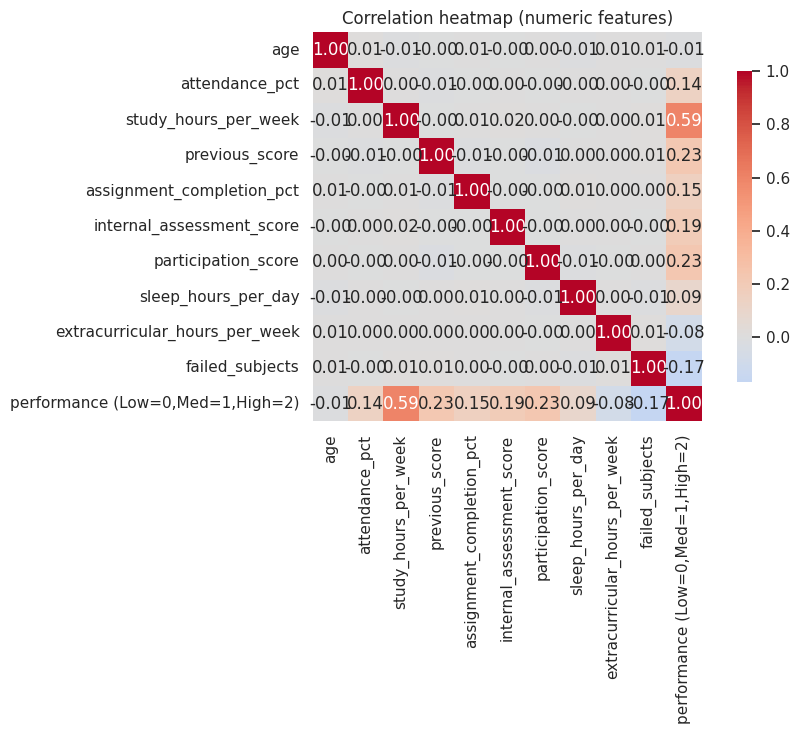

In [8]:
corr_df = df[FEATURES].copy()
corr_df["performance (Low=0,Med=1,High=2)"] = df["performance_category"].map({"Low": 0, "Medium": 1, "High": 2})
plt.figure(figsize=(10, 7.5))
sns.heatmap(corr_df.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True, cbar_kws={"shrink": .8})
plt.title("Correlation heatmap (numeric features)"); plt.tight_layout(); plt.show()

### 5.4 How do the classes differ on the most informative features?
Box plots compare each class on selected features. We pick the features with the biggest differences between class averages.

Difference between highest and lowest class mean, in standard deviations:
study_hours_per_week              1.46
participation_score               0.56
previous_score                    0.56
internal_assessment_score         0.46
failed_subjects                   0.42
assignment_completion_pct         0.38
attendance_pct                    0.35
sleep_hours_per_day               0.22
extracurricular_hours_per_week    0.20
age                               0.04


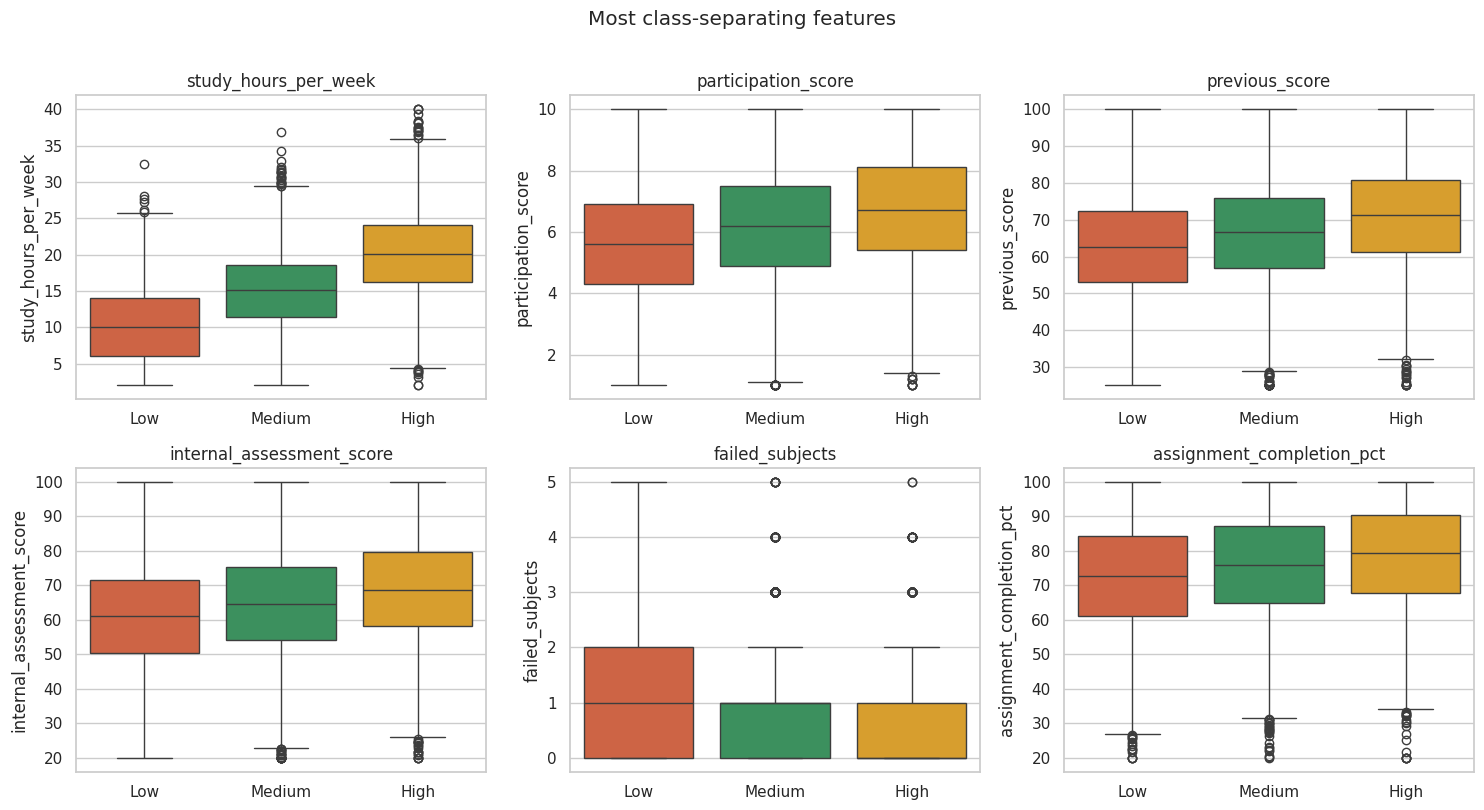

In [9]:
means = df.groupby("performance_category")[FEATURES].mean().loc[CLASS_ORDER]
spread = ((means.max() - means.min()) / df[FEATURES].std()).sort_values(ascending=False)
print("Difference between highest and lowest class mean, in standard deviations:")
print(spread.round(2).to_string())

top = list(spread.index[:6])
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.ravel(), top):
    sns.boxplot(data=df, x="performance_category", y=col, order=CLASS_ORDER, hue="performance_category",
                palette=["#e4572e", "#f3a712", "#2e9e5b"], legend=False, ax=ax)
    ax.set_xlabel(""); ax.set_title(col)
plt.suptitle("Most class-separating features", y=1.01); plt.tight_layout(); plt.show()

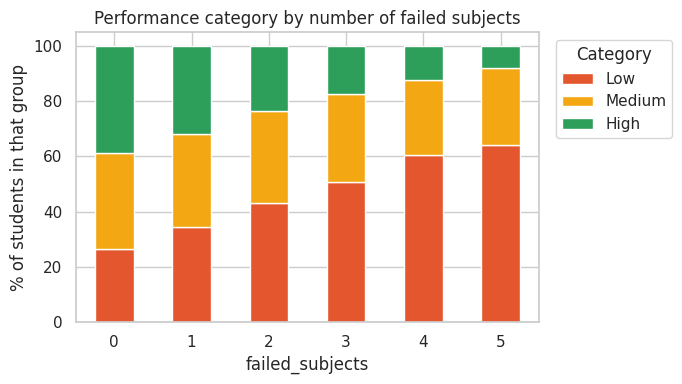

Students per failed_subjects value: {0: 6782, 1: 5338, 2: 2178, 3: 555, 4: 122, 5: 25}
(groups with 3+ failed subjects are small, so their percentages are noisy)


In [10]:
# failed_subjects is a small integer count, so a proportion table is clearer than a box plot
fs = pd.crosstab(df["failed_subjects"], df["performance_category"], normalize="index")[CLASS_ORDER] * 100
ax = fs.plot(kind="bar", stacked=True, figsize=(7, 4), color=["#e4572e", "#f3a712", "#2e9e5b"])
ax.set_ylabel("% of students in that group"); ax.set_title("Performance category by number of failed subjects")
ax.legend(title="Category", bbox_to_anchor=(1.02, 1), loc="upper left"); plt.xticks(rotation=0); plt.tight_layout(); plt.show()
print("Students per failed_subjects value:", df["failed_subjects"].value_counts().sort_index().to_dict())
print("(groups with 3+ failed subjects are small, so their percentages are noisy)")

**What the EDA tells us (read from the plots/tables above):** the classes are close to balanced; the feature values
overlap heavily between classes (the box plots overlap), so we should *not* expect perfect predictions; and the
features sit on very different numeric scales.

## 6. Feature and target selection

* **Target:** `performance_category` (Low / Medium / High).
* **Features (10):** every column except `student_id` and the target.
* `student_id` is dropped because it is an identifier. The target is never used as an input.

The label mapping is defined **explicitly in natural order** (Low = 0, Medium = 1, High = 2) instead of letting a
tool sort the names alphabetically (which would give High = 0, Low = 1, Medium = 2). The same mapping is saved to
`models/class_mapping.json` and used by the app and API.

In [11]:
TARGET = "performance_category"
INDEX_TO_LABEL = {0: "Low", 1: "Medium", 2: "High"}
LABEL_TO_INDEX = {v: k for k, v in INDEX_TO_LABEL.items()}
CLASS_NAMES = [INDEX_TO_LABEL[i] for i in range(3)]

assert set(df[TARGET].unique()) == set(LABEL_TO_INDEX), "Target labels differ from the expected Low/Medium/High"
assert TARGET not in FEATURES and "student_id" not in FEATURES
assert set(FEATURES) == set(df.columns) - {"student_id", TARGET}

X = df[FEATURES].copy()
y = df[TARGET].map(LABEL_TO_INDEX).astype(int)
print("X shape:", X.shape, "| y shape:", y.shape)
print("Features used:", FEATURES)
print("Label mapping:", INDEX_TO_LABEL)

X shape: (15000, 10) | y shape: (15000,)
Features used: ['age', 'attendance_pct', 'study_hours_per_week', 'previous_score', 'assignment_completion_pct', 'internal_assessment_score', 'participation_score', 'sleep_hours_per_day', 'extracurricular_hours_per_week', 'failed_subjects']
Label mapping: {0: 'Low', 1: 'Medium', 2: 'High'}


## 7. Train / validation / test splitting

We split **twice**, always stratified (each split keeps the same class proportions) and with a fixed seed:

1. **80 % train-pool / 20 % test.** The test set is locked away. It is used **once**, for the final evaluation.
2. The 80 % train-pool is split again into **85 % training / 15 % validation** (≈ 68 % / 12 % of all rows).
   The validation set is used to watch for overfitting, to stop training early, and to compare architectures.

Why three sets? If we picked the architecture or stopped training by looking at the test set, the test score would no
longer be an honest estimate for unseen students.

In [12]:
X_pool, X_test, y_pool, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=SEED)
X_train, X_val, y_train, y_val = train_test_split(X_pool, y_pool, test_size=0.15, stratify=y_pool, random_state=SEED)

split_table = pd.DataFrame({
    "rows": [len(X_train), len(X_val), len(X_test)],
    **{name: [(s == i).mean() * 100 for s in (y_train, y_val, y_test)] for i, name in INDEX_TO_LABEL.items()}
}, index=["train", "validation", "test"]).round(2)
split_table.columns = ["rows", "% Low", "% Medium", "% High"]
display(split_table)

# no student appears in more than one split
assert not (set(X_train.index) & set(X_val.index)) and not (set(X_train.index) & set(X_test.index)) and not (set(X_val.index) & set(X_test.index))
print("No row is shared between train, validation and test.")

,rows,% Low,% Medium,% High
train,10200,33.0,34.0,33.0
validation,1800,33.0,34.0,33.0
test,3000,33.0,34.0,33.0


No row is shared between train, validation and test.


### 7.1 Leakage check (using training rows only)

*Data leakage* means a feature secretly contains the answer. Two quick checks, done on the **training rows only** so the test set stays untouched:

1. How accurately can a small decision tree predict the class from **one single feature**? If one feature alone gave ~100 %, it would be suspicious.
2. Does the numeric part of `student_id` predict the class? It should not (it is just a label).

In [13]:
single = {}
for col in FEATURES:
    tree = DecisionTreeClassifier(max_depth=3, random_state=SEED)
    single[col] = cross_val_score(tree, X_train[[col]], y_train, cv=5, scoring="accuracy").mean()

id_num = df.loc[X_train.index, "student_id"].str.replace("STU", "", regex=False).astype(int).to_frame("student_id_number")
single["(student_id number)"] = cross_val_score(DecisionTreeClassifier(max_depth=3, random_state=SEED), id_num, y_train, cv=5).mean()

leak = pd.Series(single).sort_values(ascending=False).rename("5-fold accuracy, one feature only")
print("Chance level (always guess the biggest class): %.3f" % (y_train.value_counts(normalize=True).max()))
display(leak.round(3).to_frame())

Chance level (always guess the biggest class): 0.340


,"5-fold accuracy, one feature only"
study_hours_per_week,0.564
participation_score,0.410
previous_score,0.403
internal_assessment_score,0.392
failed_subjects,0.379
attendance_pct,0.377
assignment_completion_pct,0.373
extracurricular_hours_per_week,0.353
sleep_hours_per_day,0.349
age,0.340


**Reading the result:** if no single feature gets anywhere near 100 % and the student-id number stays near chance level,
there is no sign of an obvious leaking column. This does not prove the data is leak-free, but it is the check we can do
from the data alone. All 10 features are therefore kept.

## 8. Preprocessing and feature scaling

### Why scaling matters for an ANN
A neuron computes `output = activation(w1·x1 + w2·x2 + … + b)`. If `previous_score` is around 65 while
`failed_subjects` is around 0.8, the large numbers dominate the weighted sum, gradients for the features have very
different sizes, and gradient descent zig-zags and learns slowly or badly. **Standardisation** rewrites every feature as
`(value − mean) / standard deviation`, so each feature has mean ≈ 0 and spread ≈ 1 and they all start on an equal footing.

### Avoiding leakage
The mean and standard deviation are **fitted on the training rows only**. Validation and test rows are then transformed
with those *same* numbers (`transform`, never `fit`). The same fitted scaler is saved and re-used by the app and API.

In [14]:
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)     # fit ONLY on training rows
X_val_s = scaler.transform(X_val)
X_test_s = scaler.transform(X_test)

check = pd.DataFrame({
    "mean before": X_train.mean(), "std before": X_train.std(),
    "mean after": pd.Series(X_train_s.mean(axis=0), index=FEATURES),
    "std after": pd.Series(X_train_s.std(axis=0), index=FEATURES),
}).round(3)
display(check)
print("Scaler feature order:", list(scaler.feature_names_in_))
y_train_a, y_val_a, y_test_a = y_train.to_numpy(), y_val.to_numpy(), y_test.to_numpy()

,mean before,std before,mean after,std after
age,20.471,2.283,-0.0,1.0
attendance_pct,77.919,11.654,0.0,1.0
study_hours_per_week,15.197,6.807,-0.0,1.0
previous_score,66.656,14.695,-0.0,1.0
assignment_completion_pct,75.289,15.918,-0.0,1.0
internal_assessment_score,64.970,15.799,0.0,1.0
participation_score,6.158,1.957,-0.0,1.0
sleep_hours_per_day,6.798,1.088,-0.0,1.0
extracurricular_hours_per_week,5.099,3.280,0.0,1.0
failed_subjects,0.800,0.894,-0.0,1.0


Scaler feature order: ['age', 'attendance_pct', 'study_hours_per_week', 'previous_score', 'assignment_completion_pct', 'internal_assessment_score', 'participation_score', 'sleep_hours_per_day', 'extracurricular_hours_per_week', 'failed_subjects']


## 9. Traditional ML baseline

A **baseline** is a simple reference model: if a complicated ANN cannot beat a simple one, the extra complexity is
not justified. We train:

* a **majority-class dummy** (always predicts the most common class), the "no-skill" floor, and
* **Logistic Regression** inside a scikit-learn `Pipeline` (`StandardScaler` → `LogisticRegression`).
  It is a linear model: roughly a network with no hidden layer.

Both are trained on the **same training rows** as the ANN and evaluated on the **same test rows**.
Macro-averaged precision/recall/F1 average the three classes equally; class-wise numbers are reported as well.

In [15]:
def evaluate(y_true, y_pred):
    """Compute every metric from real predictions."""
    acc = accuracy_score(y_true, y_pred)
    p, r, f1, _ = precision_recall_fscore_support(y_true, y_pred, average="macro", zero_division=0)
    cp, cr, cf, cs = precision_recall_fscore_support(y_true, y_pred, labels=[0, 1, 2], zero_division=0)
    return {
        "accuracy": float(acc), "macro_precision": float(p), "macro_recall": float(r), "macro_f1": float(f1),
        "per_class": {INDEX_TO_LABEL[i]: {"precision": float(cp[i]), "recall": float(cr[i]), "f1": float(cf[i]), "support": int(cs[i])} for i in range(3)},
        "confusion_matrix": confusion_matrix(y_true, y_pred, labels=[0, 1, 2]).tolist(),
        "classification_report": classification_report(y_true, y_pred, labels=[0, 1, 2], target_names=CLASS_NAMES, digits=4, zero_division=0),
    }

dummy = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
res_dummy = evaluate(y_test_a, dummy.predict(X_test))

baseline = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=SEED))
baseline.fit(X_train, y_train)
base_pred = baseline.predict(X_test)
res_base = evaluate(y_test_a, base_pred)

print("Majority-class dummy  -> test accuracy: %.4f" % res_dummy["accuracy"])
print("\nLogistic Regression baseline (test set)")
print("Accuracy: %.4f | macro precision: %.4f | macro recall: %.4f | macro F1: %.4f" % (
    res_base["accuracy"], res_base["macro_precision"], res_base["macro_recall"], res_base["macro_f1"]))
print()
print(res_base["classification_report"])
print("Confusion matrix (rows = actual, columns = predicted; order Low, Medium, High):")
print(np.array(res_base["confusion_matrix"]))

Majority-class dummy  -> test accuracy: 0.3400

Logistic Regression baseline (test set)
Accuracy: 0.6950 | macro precision: 0.6956 | macro recall: 0.6964 | macro F1: 0.6958

              precision    recall  f1-score   support

         Low     0.7459    0.7768    0.7610       990
      Medium     0.5657    0.5569    0.5613      1020
        High     0.7751    0.7556    0.7652       990

    accuracy                         0.6950      3000
   macro avg     0.6956    0.6964    0.6958      3000
weighted avg     0.6943    0.6950    0.6945      3000

Confusion matrix (rows = actual, columns = predicted; order Low, Medium, High):
[[769 210  11]
 [246 568 206]
 [ 16 226 748]]


## 10. ANN architecture

### Fixed by the task
* **Input layer:** 10 neurons (one per feature).
* **Hidden layers:** `Dense` + **ReLU**. ReLU (`max(0, x)`) is cheap, avoids the vanishing-gradient problem of sigmoid/tanh in small nets and is the standard default for tabular data.
* **Output layer:** **3 neurons + Softmax** - one probability per class (Low, Medium, High), summing to 1.
* **Loss:** `sparse_categorical_crossentropy` (multi-class loss when labels are integers 0/1/2). **Optimizer:** Adam (adaptive step sizes, a robust default). **Metric:** accuracy.

### How many layers and neurons? (justified by data, not guessed)
The data is small and tabular: 10 inputs, ~10,200 training rows, 3 classes. A very large network would just memorise noise.
So we compare four *small* candidate designs and choose using **validation loss only** (never the test set):

| Candidate | Hidden layers |
|---|---|
| A | 16 |
| B | 32 → 16 |
| C | 64 → 32 |
| D | 64 → 32 → 16 |

**Selection rule (decided before looking at results):** take the candidate with the lowest validation loss, but if a
simpler (fewer-parameter) model is within **1 %** of that best validation loss, prefer the simpler one - simpler models
overfit less and are easier to explain.

In [16]:
N_FEATURES, N_CLASSES = len(FEATURES), 3
BATCH_SIZE, MAX_EPOCHS, PATIENCE, LR = 64, 100, 10, 1e-3

def build_model(hidden_units):
    model = keras.Sequential(name="student_performance_ann")
    model.add(keras.Input(shape=(N_FEATURES,)))
    for units in hidden_units:
        model.add(keras.layers.Dense(units, activation="relu"))
    model.add(keras.layers.Dense(N_CLASSES, activation="softmax"))
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=LR),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model

CANDIDATES = {"A: 16": [16], "B: 32-16": [32, 16], "C: 64-32": [64, 32], "D: 64-32-16": [64, 32, 16]}
search_rows = []
for name, units in CANDIDATES.items():
    keras.utils.set_random_seed(SEED)
    m = build_model(units)
    stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=PATIENCE, restore_best_weights=True)
    h = m.fit(X_train_s, y_train_a, validation_data=(X_val_s, y_val_a), epochs=MAX_EPOCHS,
              batch_size=BATCH_SIZE, callbacks=[stop], verbose=0)
    best_i = int(np.argmin(h.history["val_loss"]))
    search_rows.append({"candidate": name, "hidden_units": units, "parameters": m.count_params(),
                        "epochs_run": len(h.history["loss"]), "best_epoch": best_i + 1,
                        "val_loss": h.history["val_loss"][best_i], "val_accuracy": h.history["val_accuracy"][best_i],
                        "train_accuracy_at_best": h.history["accuracy"][best_i]})

search = pd.DataFrame(search_rows)
best_val = search["val_loss"].min()
eligible = search[search["val_loss"] <= best_val * 1.01]
chosen = eligible.sort_values("parameters").iloc[0]
HIDDEN_UNITS = list(chosen["hidden_units"])
display(search.drop(columns="hidden_units").round(4))
print(f"Lowest validation loss: {best_val:.4f}. Candidates within 1% of it: {list(eligible['candidate'])}")
print(f"Chosen architecture (simplest eligible): {chosen['candidate']} -> hidden layers {HIDDEN_UNITS}")

E0000 00:00:1792258396.016651    4433 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)
E0000 00:00:1792258396.140604    4433 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


E0000 00:00:1792258430.731170    4433 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


E0000 00:00:1792258441.392907    4433 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


E0000 00:00:1792258448.790594    4433 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


,candidate,parameters,epochs_run,best_epoch,val_loss,val_accuracy,train_accuracy_at_best
0,A: 16,227,91,81,0.6403,0.6933,0.6925
1,B: 32-16,931,24,14,0.6492,0.6894,0.6910
2,C: 64-32,2883,17,7,0.6529,0.6894,0.6919
3,D: 64-32-16,3363,14,4,0.6506,0.6889,0.6893


Lowest validation loss: 0.6403. Candidates within 1% of it: ['A: 16']
Chosen architecture (simplest eligible): A: 16 -> hidden layers [16]


## 11. ANN training

We re-build the chosen architecture from a fresh seed and train it with:

* **Epochs:** up to 100 (one epoch = the network sees all training rows once).
* **Batch size:** 64 (weights are updated after every 64 rows).
* **Early stopping:** stop when validation loss has not improved for 10 epochs and go back to the best weights.
* **Model checkpoint:** the best model (lowest validation loss) is written straight to `models/student_performance.keras`.

During each step the network does **forward propagation** (inputs → hidden layers → softmax probabilities), measures the
error with the loss function, then **backpropagation** computes how much each weight contributed to that error and
Adam nudges the weights to reduce it.

In [17]:
MODEL_PATH = MODEL_DIR / "student_performance.keras"
if MODEL_PATH.exists():
    MODEL_PATH.unlink()                       # make sure the saved file really comes from this run

keras.utils.set_random_seed(SEED)
ann = build_model(HIDDEN_UNITS)
ann.summary()

callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=PATIENCE, restore_best_weights=True),
    keras.callbacks.ModelCheckpoint(filepath=str(MODEL_PATH), monitor="val_loss", save_best_only=True),
]
history = ann.fit(X_train_s, y_train_a, validation_data=(X_val_s, y_val_a), epochs=MAX_EPOCHS,
                  batch_size=BATCH_SIZE, callbacks=callbacks, verbose=2)

epochs_run = len(history.history["loss"])
best_epoch = int(np.argmin(history.history["val_loss"])) + 1
print(f"\nEpochs run: {epochs_run} | best epoch (lowest val_loss): {best_epoch}")

Model: "student_performance_ann"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_12 (Dense)                │ (None, 16)             │           176 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 3)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 227 (908.00 B)

 Trainable params: 227 (908.00 B)

 Non-trainable params: 0 (0.00 B)

...

Epoch 90/100


160/160 - 0s - 2ms/step - accuracy: 0.6928 - loss: 0.6547 - val_accuracy: 0.6928 - val_loss: 0.6405


Epoch 91/100


160/160 - 0s - 2ms/step - accuracy: 0.6924 - loss: 0.6547 - val_accuracy: 0.6928 - val_loss: 0.6405



Epochs run: 91 | best epoch (lowest val_loss): 81


## 12. Evaluation on unseen test data

First the learning curves. If training loss keeps falling while validation loss rises, the model is **overfitting**.
If both stay high, it is **underfitting**.

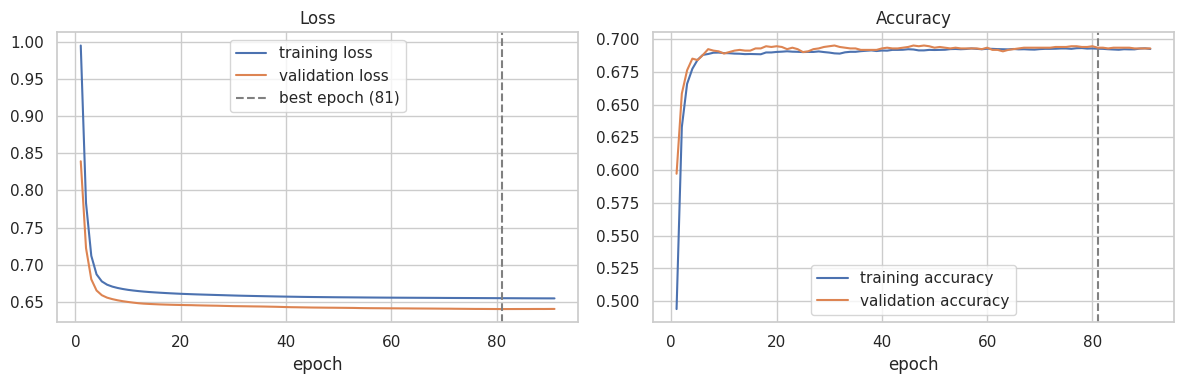

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
ep = range(1, epochs_run + 1)
axes[0].plot(ep, history.history["loss"], label="training loss"); axes[0].plot(ep, history.history["val_loss"], label="validation loss")
axes[0].axvline(best_epoch, ls="--", c="grey", label=f"best epoch ({best_epoch})"); axes[0].set_title("Loss"); axes[0].set_xlabel("epoch"); axes[0].legend()
axes[1].plot(ep, history.history["accuracy"], label="training accuracy"); axes[1].plot(ep, history.history["val_accuracy"], label="validation accuracy")
axes[1].axvline(best_epoch, ls="--", c="grey"); axes[1].set_title("Accuracy"); axes[1].set_xlabel("epoch"); axes[1].legend()
plt.tight_layout(); plt.savefig(REPORT_DIR / "training_curves.png", dpi=150); plt.show()

Now we load the **saved best checkpoint from disk** (this is exactly the model the app will use) and evaluate it
on the training, validation and test sets. Only the test numbers are used for the final comparison.

In [19]:
best_model = keras.models.load_model(MODEL_PATH)

def predict_classes(model, X_scaled):
    probs = model.predict(X_scaled, verbose=0)
    return probs, probs.argmax(axis=1)

_, pred_train = predict_classes(best_model, X_train_s)
_, pred_val = predict_classes(best_model, X_val_s)
ann_probs_test, ann_pred = predict_classes(best_model, X_test_s)

acc_train, acc_val = accuracy_score(y_train_a, pred_train), accuracy_score(y_val_a, pred_val)
res_ann = evaluate(y_test_a, ann_pred)

print("ANN accuracy  train: %.4f | validation: %.4f | TEST: %.4f" % (acc_train, acc_val, res_ann["accuracy"]))
print("ANN TEST macro precision: %.4f | macro recall: %.4f | macro F1: %.4f\n" % (
    res_ann["macro_precision"], res_ann["macro_recall"], res_ann["macro_f1"]))
print(res_ann["classification_report"])

E0000 00:00:1792258499.710130    4433 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


ANN accuracy  train: 0.6919 | validation: 0.6933 | TEST: 0.6947
ANN TEST macro precision: 0.6948 | macro recall: 0.6961 | macro F1: 0.6953

              precision    recall  f1-score   support

         Low     0.7473    0.7798    0.7632       990
      Medium     0.5681    0.5559    0.5619      1020
        High     0.7688    0.7525    0.7606       990

    accuracy                         0.6947      3000
   macro avg     0.6948    0.6961    0.6953      3000
weighted avg     0.6935    0.6947    0.6939      3000



## 13. Baseline comparison

Both models were evaluated on the **same 3,000 test students**. The `±` column is an approximate 95 % margin of error
for accuracy caused only by the test-set size (`1.96·√(acc·(1−acc)/n)`). Differences smaller than that margin
should not be read as one model being genuinely better.

In [20]:
n_test = len(y_test_a)
def margin(acc): return 1.96 * np.sqrt(acc * (1 - acc) / n_test)

comparison = pd.DataFrame({
    "Majority-class dummy": res_dummy, "Logistic Regression": res_base, "ANN (Keras)": res_ann,
}).T[["accuracy", "macro_precision", "macro_recall", "macro_f1"]].astype(float)
comparison["accuracy ± (95%)"] = [margin(a) for a in comparison["accuracy"]]
display(comparison.round(4))

rows = []
for cls in CLASS_NAMES:
    rows.append({"class": cls, "support": res_ann["per_class"][cls]["support"],
                 **{f"LogReg {m}": res_base["per_class"][cls][m] for m in ("precision", "recall", "f1")},
                 **{f"ANN {m}": res_ann["per_class"][cls][m] for m in ("precision", "recall", "f1")}})
per_class_cmp = pd.DataFrame(rows).set_index("class")
print("Class-wise test metrics:")
display(per_class_cmp.round(4))

,accuracy,macro_precision,macro_recall,macro_f1,accuracy ± (95%)
Majority-class dummy,0.3400,0.1133,0.3333,0.1692,0.0170
Logistic Regression,0.6950,0.6956,0.6964,0.6958,0.0165
ANN (Keras),0.6947,0.6948,0.6961,0.6953,0.0165


Class-wise test metrics:


,support,LogReg precision,LogReg recall,LogReg f1,ANN precision,ANN recall,ANN f1
class,,,,,,,
Low,990,0.7459,0.7768,0.7610,0.7473,0.7798,0.7632
Medium,1020,0.5657,0.5569,0.5613,0.5681,0.5559,0.5619
High,990,0.7751,0.7556,0.7652,0.7688,0.7525,0.7606


## 14. Confusion matrices

Rows = true class, columns = predicted class. The diagonal counts correct predictions; off-diagonal cells show which
classes get confused. The picture is saved to `reports/confusion_matrix.png` from the actual test predictions.

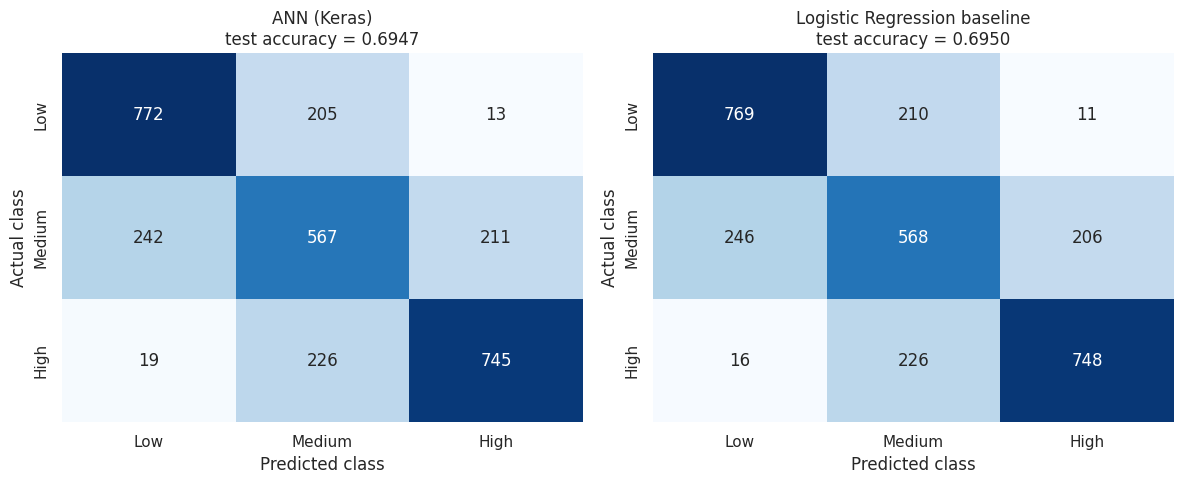

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, (title, res) in zip(axes, [("ANN (Keras)", res_ann), ("Logistic Regression baseline", res_base)]):
    cm = np.array(res["confusion_matrix"])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, cbar=False, ax=ax)
    ax.set_title(f"{title}\ntest accuracy = {res['accuracy']:.4f}"); ax.set_xlabel("Predicted class"); ax.set_ylabel("Actual class")
plt.tight_layout(); plt.savefig(REPORT_DIR / "confusion_matrix.png", dpi=150); plt.show()

## 15. Model saving

Saved artifacts (all loaded - never re-trained - by `app.py` and `api.py` through `predictor.py`):

| File | Purpose |
|---|---|
| `models/student_performance.keras` | the trained ANN (already written by the checkpoint callback) |
| `models/scaler.joblib` | the `StandardScaler` fitted on training rows |
| `models/class_mapping.json` | 0/1/2 → Low/Medium/High |
| `models/training_metadata.json` | feature order, training feature ranges, library versions (an extra helper file; used for input-range warnings and consistency checks) |
| `reports/results.json` | all real metrics from this run |

In [22]:
joblib.dump(scaler, MODEL_DIR / "scaler.joblib")
with open(MODEL_DIR / "class_mapping.json", "w", encoding="utf-8") as f:
    json.dump({"index_to_label": {str(k): v for k, v in INDEX_TO_LABEL.items()},
               "label_to_index": LABEL_TO_INDEX}, f, indent=2)

metadata = {
    "trained_at_utc": datetime.now(timezone.utc).strftime("%Y-%m-%d %H:%M:%S"),
    "random_seed": SEED,
    "feature_columns": FEATURES,
    "training_feature_ranges": {c: {"min": float(X_train[c].min()), "max": float(X_train[c].max())} for c in FEATURES},
    "hidden_units": HIDDEN_UNITS,
    "environment": ENV,
}
with open(MODEL_DIR / "training_metadata.json", "w", encoding="utf-8") as f:
    json.dump(metadata, f, indent=2)

results = {
    "random_seed": SEED,
    "dataset": {"file": "data/student_data.csv", "rows": int(len(df)), "features": FEATURES, "target": TARGET,
                "class_counts": {k: int(v) for k, v in df[TARGET].value_counts().items()}},
    "split": {"train_rows": int(len(X_train)), "validation_rows": int(len(X_val)), "test_rows": int(len(X_test)), "stratified": True},
    "environment": ENV,
    "architecture_search": [{k: (v if not isinstance(v, (np.integer, np.floating)) else v.item()) for k, v in r.items()} for r in search_rows],
    "ann_config": {"hidden_units": HIDDEN_UNITS, "hidden_activation": "relu", "output_activation": "softmax", "loss": "sparse_categorical_crossentropy",
                   "optimizer": "adam", "learning_rate": LR, "batch_size": BATCH_SIZE, "max_epochs": MAX_EPOCHS, "early_stopping_patience": PATIENCE,
                   "epochs_run": epochs_run, "best_epoch": best_epoch, "parameters": int(best_model.count_params())},
    "ann_accuracy_by_split": {"train": float(acc_train), "validation": float(acc_val), "test": float(res_ann["accuracy"])},
    "majority_class_dummy": {k: v for k, v in res_dummy.items() if k != "classification_report"},
    "baseline_logistic_regression": {k: v for k, v in res_base.items() if k != "classification_report"},
    "ann": {k: v for k, v in res_ann.items() if k != "classification_report"},
}
with open(REPORT_DIR / "results.json", "w", encoding="utf-8") as f:
    json.dump(results, f, indent=2)
print("Saved:", sorted(p.name for p in MODEL_DIR.iterdir() if p.is_file()))

Saved: ['class_mapping.json', 'scaler.joblib', 'student_performance.keras', 'training_metadata.json']


### Verify the saved files work

1. Reload the saved ANN and scaler and confirm they reproduce the in-memory predictions.
2. Use the shared `predictor.py` (the exact code used by the app and API) on real test rows and confirm it gives the same answers as this notebook.
3. Load everything in a **fresh Python process** and make one prediction for the *example input from the project PDF* (an illustrative input, **not** a real dataset record or a verified prediction).

In [23]:
# 1. reload ANN + scaler
reloaded_model = keras.models.load_model(MODEL_PATH)
reloaded_scaler = joblib.load(MODEL_DIR / "scaler.joblib")
assert np.allclose(reloaded_scaler.transform(X_test), X_test_s)
assert np.allclose(reloaded_model.predict(X_test_s, verbose=0), ann_probs_test, atol=1e-5)
print("1) Reloaded ANN + scaler reproduce the notebook's test probabilities.")

# 2. shared predictor.py on raw (unscaled) test rows
from predictor import Predictor
predictor = Predictor()
sample = X_test.iloc[:200]
via_predictor = [predictor.predict(row.to_dict())["predicted_class"] for _, row in sample.iterrows()]
expected = [INDEX_TO_LABEL[i] for i in ann_pred[:200]]
assert via_predictor == expected
print("2) predictor.py (used by Streamlit + FastAPI) matches the notebook on 200 test students.")

# 3. fresh process
EXAMPLE = {"age": 19, "attendance_pct": 82.0, "study_hours_per_week": 12.5, "previous_score": 71.0,
           "assignment_completion_pct": 80.0, "internal_assessment_score": 68.0, "participation_score": 7.0,
           "sleep_hours_per_day": 7.0, "extracurricular_hours_per_week": 4.0, "failed_subjects": 0}
snippet = ("import sys, json; sys.path.insert(0, %r)\n"
           "from predictor import Predictor\n"
           "print(json.dumps(Predictor().predict(%r)))" % (str(PROJECT_ROOT), EXAMPLE))
proc = subprocess.run([sys.executable, "-c", snippet], capture_output=True, text=True, env={**os.environ, "TF_CPP_MIN_LOG_LEVEL": "3"})
assert proc.returncode == 0, proc.stderr[-2000:]
print("3) Fresh-process prediction for the illustrative example input:")
print("  ", proc.stdout.strip().splitlines()[-1])

1) Reloaded ANN + scaler reproduce the notebook's test probabilities.


E0000 00:00:1792258504.718996    4433 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


E0000 00:00:1792258509.724582    4433 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


E0000 00:00:1792258514.729179    4433 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


2) predictor.py (used by Streamlit + FastAPI) matches the notebook on 200 test students.


3) Fresh-process prediction for the illustrative example input:
   {"predicted_class": "Medium", "confidence": 0.5162980556488037, "probabilities": {"Low": 0.09990724921226501, "Medium": 0.5162980556488037, "High": 0.3837946653366089}, "warnings": []}


## 16. Final observations

The observations below are **generated from the measured numbers** (so they always match what was actually run), and
the same text is written into `reports/evaluation_report.md`.

In [24]:
obs = []
a, b, d0 = res_ann, res_base, res_dummy
diff = a["macro_f1"] - b["macro_f1"]
ci_a, ci_b = margin(a["accuracy"]) * 100, margin(b["accuracy"]) * 100
if abs(diff) < 0.01:
    obs.append(f"**Which model is better?** On the same {n_test} test students the ANN (macro-F1 {a['macro_f1']:.4f}, accuracy {a['accuracy']:.4f}) and Logistic Regression "
               f"(macro-F1 {b['macro_f1']:.4f}, accuracy {b['accuracy']:.4f}) are practically tied: the macro-F1 difference is {diff*100:+.2f} percentage points, which is smaller than the "
               f"roughly ±{max(ci_a, ci_b):.1f} point sampling uncertainty of this test set. These results do not show that the ANN is better than the simple baseline.")
elif diff > 0:
    obs.append(f"**Which model is better?** The ANN scored higher than Logistic Regression on macro-F1 ({a['macro_f1']:.4f} vs {b['macro_f1']:.4f}, a gap of {diff*100:+.2f} points; accuracy {a['accuracy']:.4f} vs {b['accuracy']:.4f}). "
               f"The accuracy margin of error on {n_test} test students is about ±{max(ci_a, ci_b):.1f} points, and this is a single split with a single seed, so treat the gap as indicative, not definitive.")
else:
    obs.append(f"**Which model is better?** Logistic Regression scored higher than the ANN on macro-F1 ({b['macro_f1']:.4f} vs {a['macro_f1']:.4f}, a gap of {-diff*100:.2f} points; accuracy {b['accuracy']:.4f} vs {a['accuracy']:.4f}). "
               f"On this tabular dataset the simpler model was at least as good, so the extra complexity of the ANN was not rewarded here.")

obs.append(f"**Versus no skill:** always predicting the most common class gives accuracy {d0['accuracy']:.4f}; both trained models are clearly above that floor "
           f"({b['accuracy']:.4f} and {a['accuracy']:.4f})." if min(a['accuracy'], b['accuracy']) > d0['accuracy'] + 0.05 else
           f"**Versus no skill:** always predicting the most common class gives accuracy {d0['accuracy']:.4f}; the trained models are not far above that floor, so the features carry limited signal.")

for name, r in (("ANN", a), ("Logistic Regression", b)):
    f1s = {c: r["per_class"][c]["f1"] for c in CLASS_NAMES}
    hi, lo = max(f1s, key=f1s.get), min(f1s, key=f1s.get)
    obs.append(f"**Class differences ({name}):** best class is {hi} (F1 {f1s[hi]:.3f}), weakest is {lo} (F1 {f1s[lo]:.3f}); gap {abs(f1s[hi]-f1s[lo]):.3f}.")

cm = np.array(a["confusion_matrix"]); off = cm.copy(); np.fill_diagonal(off, 0)
i, j = np.unravel_index(off.argmax(), off.shape)
obs.append(f"**Most common ANN confusion:** {off[i, j]} students whose true class was {CLASS_NAMES[i]} were predicted as {CLASS_NAMES[j]}.")

gap_tv, gap_vt = acc_train - acc_val, acc_val - res_ann["accuracy"]
if gap_tv > 0.03:
    fit = f"training accuracy ({acc_train:.4f}) is {gap_tv*100:.1f} points above validation accuracy ({acc_val:.4f}), which suggests some overfitting"
else:
    fit = f"training accuracy ({acc_train:.4f}), validation accuracy ({acc_val:.4f}) and test accuracy ({res_ann['accuracy']:.4f}) are close to each other, so there is no strong sign of overfitting"
under = (" Accuracy is modest in absolute terms. Making the network larger did not lower validation loss in the architecture comparison, and the simple linear baseline scores about the same, "
         "which is consistent with the classes overlapping heavily in these features (or the labels containing noise) rather than the network being too small. This is an interpretation, not something the numbers prove.") if res_ann["accuracy"] < 0.80 else ""
obs.append(f"**Overfitting / underfitting:** {fit}. Early stopping picked epoch {best_epoch} of {epochs_run} run.{under}")

if any(v >= 0.9999 for v in (a["accuracy"], a["macro_precision"], a["macro_recall"], a["macro_f1"])):
    obs.append("**Caution:** a metric reached 100 %. That does not mean the model is perfect; check for leakage and remember the test set is finite.")

obs.append("**Limitations:** (1) One dataset, one random split and one seed: results could shift slightly with another split. "
           "(2) The data is unusually clean (no missing values, no duplicates, near-perfectly balanced classes), which is uncommon in real school records, so the results may not transfer to real students. "
           "(3) We do not know how `performance_category` was defined; the model learns the dataset's labelling, not true ability. "
           "(4) Features are correlated with the category but this does not prove cause and effect. "
           "(5) The tool must not be used for real decisions about students; it is for learning. "
           "(6) Probabilities from a softmax output are model scores, not guaranteed real-world certainty.")

for o in obs: print("-", o, "\n")

- **Which model is better?** On the same 3000 test students the ANN (macro-F1 0.6953, accuracy 0.6947) and Logistic Regression (macro-F1 0.6958, accuracy 0.6950) are practically tied: the macro-F1 difference is -0.06 percentage points, which is smaller than the roughly ±1.6 point sampling uncertainty of this test set. These results do not show that the ANN is better than the simple baseline. 

- **Versus no skill:** always predicting the most common class gives accuracy 0.3400; both trained models are clearly above that floor (0.6950 and 0.6947). 

- **Class differences (ANN):** best class is Low (F1 0.763), weakest is Medium (F1 0.562); gap 0.201. 

- **Class differences (Logistic Regression):** best class is High (F1 0.765), weakest is Medium (F1 0.561); gap 0.204. 

- **Most common ANN confusion:** 242 students whose true class was Medium were predicted as Low. 

- **Overfitting / underfitting:** training accuracy (0.6919), validation accuracy (0.6933) and test accuracy (0.6947) are

In [25]:
def md_table(df_, floatfmt="{:.4f}"):
    cols = [df_.index.name or ""] + list(df_.columns)
    lines = ["| " + " | ".join(str(c) for c in cols) + " |", "|" + "|".join("---" for _ in cols) + "|"]
    for i, idx in enumerate(df_.index):
        cells = [str(idx)]
        for col in df_.columns:
            v = df_[col].iloc[i]          # per-column access keeps integer columns as integers
            cells.append(floatfmt.format(v) if isinstance(v, (float, np.floating)) else str(v))
        lines.append("| " + " | ".join(cells) + " |")
    return "\n".join(lines)

def cm_table(res):
    t = pd.DataFrame(res["confusion_matrix"], index=[f"actual {c}" for c in CLASS_NAMES], columns=[f"pred {c}" for c in CLASS_NAMES])
    return md_table(t, "{}")

arch_tbl = search.drop(columns="hidden_units").set_index("candidate")[["parameters", "epochs_run", "best_epoch", "val_loss", "val_accuracy"]]
cmp_tbl = comparison.copy(); cmp_tbl["accuracy ± (95%)"] = cmp_tbl["accuracy ± (95%)"].map(lambda v: f"±{v:.4f}")
cmp_tbl.index.name = "model"
class_tbl = per_class_cmp.copy()
dist = df[TARGET].value_counts()

report = f"""# Evaluation Report — AI-Based Student Performance Risk Predictor

_Generated automatically by `notebooks/ann_training.ipynb` from the actual run on {metadata['trained_at_utc']} UTC (seed {SEED}).
Re-running the notebook regenerates every number below. Small differences can appear on a different machine or library version._

## 1. Dataset overview
* File: `data/student_data.csv` — **{len(df):,} rows**, 12 columns, supplied with the assignment and not modified.
* Target: `{TARGET}` — Low: {dist['Low']:,}, Medium: {dist['Medium']:,}, High: {dist['High']:,}.
* 10 input features: {", ".join(f"`{c}`" for c in FEATURES)}.
* `student_id` is an identifier (unique per row) and is **not** used as a feature.
* Data quality checks: 0 missing values, 0 duplicate rows, all values within valid ranges (see notebook section 4).
* Leakage check (training rows only): best single feature alone reaches {leak.iloc[0]:.3f} 5-fold accuracy (`{leak.index[0]}`); the student-id number alone reaches {leak['(student_id number)']:.3f} (chance ≈ {y_train.value_counts(normalize=True).max():.3f}).

## 2. Preprocessing steps
1. Features and target separated; label mapping fixed as Low=0, Medium=1, High=2.
2. Stratified split with seed {SEED}: train {len(X_train):,} / validation {len(X_val):,} / test {len(X_test):,} rows. The test set was used only for the final evaluation.
3. `StandardScaler` fitted on the training rows only, then applied unchanged to validation, test and (via `models/scaler.joblib`) to every inference request.

## 3. Baseline models
* **Majority-class dummy** (always predicts the most common class) — the no-skill floor.
* **Logistic Regression** (`StandardScaler` → `LogisticRegression`, `max_iter=1000`), trained on the same {len(X_train):,} training rows as the ANN.

## 4. ANN architecture
Feed-forward network: Input({N_FEATURES}) → {" → ".join(f"Dense({u}, ReLU)" for u in HIDDEN_UNITS)} → Dense(3, Softmax); {best_model.count_params():,} trainable parameters.

Architecture choice (validation set only; rule: lowest validation loss, preferring a simpler model if within 1 %):

{md_table(arch_tbl)}

Chosen: **{chosen['candidate']}**.

## 5. Training configuration
Loss `sparse_categorical_crossentropy`; optimizer Adam (learning rate {LR}); batch size {BATCH_SIZE}; up to {MAX_EPOCHS} epochs; early stopping on validation loss (patience {PATIENCE}, restore best weights); model checkpoint on best validation loss.
Training ran {epochs_run} epochs; best epoch {best_epoch}. Learning curves: `reports/training_curves.png`.

## 6. Evaluation methodology
Both models were evaluated once on the same untouched test set ({n_test:,} students). Metrics: accuracy; macro-averaged precision, recall, F1 (the three classes weighted equally); class-wise precision/recall/F1; confusion matrix. The ± column is an approximate 95 % margin of error for accuracy due to test-set size only.

## 7. Actual evaluation metrics (test set)
{md_table(cmp_tbl)}

ANN accuracy by split — train {acc_train:.4f}, validation {acc_val:.4f}, test {res_ann['accuracy']:.4f}.

### Class-wise metrics
{md_table(class_tbl)}

### ANN classification report
```
{res_ann['classification_report']}```

### Logistic Regression classification report
```
{res_base['classification_report']}```

## 8. Confusion matrices (rows = actual, columns = predicted)
![Confusion matrices](confusion_matrix.png)

ANN:

{cm_table(res_ann)}

Logistic Regression:

{cm_table(res_base)}

## 9. Baseline versus ANN
{obs[0]}

{obs[1]}

## 10. Observations
{chr(10).join("* " + o for o in obs[2:-1])}

## 11. Limitations
{obs[-1]}

## 12. Conclusion
The conclusions are limited to what was measured: {"the ANN and the Logistic Regression baseline performed about equally" if abs(diff) < 0.01 else ("the ANN scored higher than the baseline" if diff > 0 else "the baseline scored higher than the ANN")} on this dataset's test split (macro-F1 {a['macro_f1']:.4f} for the ANN vs {b['macro_f1']:.4f} for Logistic Regression). The ANN is a working, saved, reloadable model that serves predictions through the Streamlit app and the FastAPI endpoint, but it is an educational model whose outputs are estimates, not guarantees about any student.
"""
with open(REPORT_DIR / "evaluation_report.md", "w", encoding="utf-8") as f:
    f.write(report)
print("Wrote reports/evaluation_report.md (", len(report), "characters )")

Wrote reports/evaluation_report.md ( 7847 characters )


### Summary of what this notebook produced

* `models/student_performance.keras`, `models/scaler.joblib`, `models/class_mapping.json`, `models/training_metadata.json`
* `reports/results.json`, `reports/evaluation_report.md`, `reports/confusion_matrix.png`, `reports/training_curves.png`

Next steps: start the Streamlit app (`streamlit run app.py`) or the API (`uvicorn api:app`). They **load** these files; they do not train.